# ИССЛЕДОВАНИЕ ДАННЫХ HR-АГЕНТСТВА

## Вводная

HR-агентство изучает тренды на рынке труда в IT. Компания хочет провести исследование на основе данных о зарплатах в сфере Data Science за 2020–2022 годы и получить некоторые выводы.

## Данные

data/ds_salaries.zip (упакованный csv)

* `work_year`	Год, в котором была выплачена зарплата.
* `experience_level`	Опыт работы на этой должности в течение года со следующими возможными значениями:
    * **EN** — Entry-level/Junior
    * **MI** — Mid-level/Intermediate
    * **SE** — Senior-level/Expert
    * **EX** — Executive-level/Director
* `employment_type`	Тип трудоустройства для этой роли:
    * **PT** — неполный рабочий день
    * **FT** — полный рабочий день
    * **CT** — контракт
    * **FL** — фриланс
* `job_title`	Роль, в которой соискатель работал в течение года.
* `salary`	Общая выплаченная валовая сумма заработной платы.
* `salary_currency`	Валюта выплачиваемой заработной платы в виде кода валюты ISO 4217.
* `salary_in_usd`	Зарплата в долларах США (валютный курс, делённый на среднее значение курса доллара США за соответствующий год через fxdata.foorilla.com).
* `employee_residence`	Основная страна проживания сотрудника в течение рабочего года в виде кода страны ISO 3166.
* `remote_ratio`	Общий объём работы, выполняемой удалённо. Возможные значения:
    * **0** — удалённой работы нет (менее 20 %);
    * **50** — частично удалённая работа;
    * **100** — полностью удалённая работа (более 80 %).
* `company_location`	Страна главного офиса работодателя или филиала по контракту в виде кода страны ISO 3166.
* `company_size`	Среднее количество людей, работавших в компании в течение года:
    * **S** — менее 50 сотрудников (небольшая компания);
    * **M** — от 50 до 250 сотрудников (средняя компания);
    * **L** — более 250 сотрудников (крупная компания).

## Задание

Исследуйте данные и сделайте выводы по полученным результатам. Подкрепите свои рассуждения и выводы визуализациями и с помощью статистического тестирования проверьте, являются ли выводы статистически значимыми.

1. Выяснить, какие факторы влияют на зарплату специалиста Data Scientist.
2. Ответить на **ключевые вопросы HR-агентства**:
    * Наблюдается ли ежегодный рост зарплат у специалистов Data Scientist?
    * Как соотносятся зарплаты Data Scientist и Data Engineer в 2022 году?
    * Как соотносятся зарплаты специалистов Data Scientist в компаниях различных размеров?
    * Есть ли связь между наличием должностей Data Scientist и Data Engineer и размером компании?

Если вы найдёте в данных интересные закономерности, также отметьте их в своём анализе.


Продемонстрируйте использование разных тестов для проверки статистической значимости сделанных выводов:


* тесты для количественного признака:
  * для одной выборки;
  * для двух выборок;
  * для нескольких выборок;
* тест для категориальных признаков.

_Результатом работы должен стать ноутбук (IPYNB-файл) с кодом для исследования, а также с выводами и рассуждениями, полученными на основе разведывательного анализа._

## Работа

### Импорты

In [256]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)

### Константы

In [276]:
# Порог значимости. Поскольку данные некритичные, не ядерная физика в конце ноцов, то берём стандартный. 
# Разведку я проводил  на .1, но ничего толкового не глянулось, по=этому .05
P_VALUE_THRESHOLD = .05

### Загрузка

In [258]:
# загружаем данные и выводим первичную информацию
df_original = pd.read_csv('data/ds_salaries.zip')
df_original.info()
display(df_original.head())
display(df_original.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          607 non-null    int64 
 1   work_year           607 non-null    int64 
 2   experience_level    607 non-null    object
 3   employment_type     607 non-null    object
 4   job_title           607 non-null    object
 5   salary              607 non-null    int64 
 6   salary_currency     607 non-null    object
 7   salary_in_usd       607 non-null    int64 
 8   employee_residence  607 non-null    object
 9   remote_ratio        607 non-null    int64 
 10  company_location    607 non-null    object
 11  company_size        607 non-null    object
dtypes: int64(5), object(7)
memory usage: 57.0+ KB


,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,607.0,NaN,NaN,NaN,303.0,175.370085,0.0,151.5,303.0,454.5,606.0
work_year,607.0,NaN,NaN,NaN,2021.405272,0.692133,2020.0,2021.0,2022.0,2022.0,2022.0
experience_level,607,4,SE,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,607,4,FT,588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,607,50,Data Scientist,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,607.0,NaN,NaN,NaN,324000.062603,1544357.486636,4000.0,70000.0,115000.0,165000.0,30400000.0
salary_currency,607,17,USD,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_in_usd,607.0,NaN,NaN,NaN,112297.869852,70957.259411,2859.0,62726.0,101570.0,150000.0,600000.0
employee_residence,607,57,US,332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_ratio,607.0,NaN,NaN,NaN,70.92257,40.70913,0.0,50.0,100.0,100.0,100.0


In [259]:
display(df_original['work_year'].unique())
display(df_original['remote_ratio'].unique())

array([2020, 2021, 2022])

array([  0,  50, 100])

### Очистка и наполнение

В датасете 607 строк, пропусков нет. Датасет маленький, результаты будут так себе. `Unnamed: 0` индекс из csv - удаляем. `experience_level`, `employment_type`, `job_title`, `salary_currency`, `employee_residence`, `company_location`, `company_size` - однозначно категории. `remote_ratio` - число, но как число нам абсолюно никакой информации не дает, по-этому - категория. `work_year` - вроде бы тоже, но это временной период, по-этому оставлю числом.

In [260]:
# Чистка, lc и категорирование
def clean_and_categorize(df: pd.DataFrame, columns: list[str]):
    for col in columns:
        if col not in df.columns:
            continue
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            df[col] = (
                df[col]
                .astype(str)
                .str.strip()
                .str.lower()
                .astype('category')
            )
        elif pd.api.types.is_string_dtype(df[col]):
            df[col] = (
                df[col]
                .str.strip()
                .str.lower()
                .astype('category')
            )
        elif pd.api.types.is_numeric_dtype(df[col]) or pd.api.types.is_bool_dtype(df[col]):
            df[col] = df[col].astype('category')
            
    return df

In [ ]:
# Так как дроп возвращает эни, то даем здесь типизацию, 
# чтобы была подсветка синтаксиса в дальнейшем
df_work: pd.DataFrame = df_original.drop(columns=['Unnamed: 0'])



categorical_columns = [
    'experience_level', 'employment_type', 'job_title', 'salary_currency',
    'employee_residence', 'remote_ratio', 'company_location', 'company_size',
]
df_work = clean_and_categorize(df_work, categorical_columns)


print(f'Размер датасета после удаления индекса: {df_work.shape}')
display(df_work.dtypes.to_frame('dtype'))
# выыодим лписание датасета в виде горизонтальной таблицы
display(df_work.describe(include='all').T)
display(df_work.head())

Размер датасета после удаления индекса: (607, 11)


,dtype
work_year,int64
experience_level,category
employment_type,category
job_title,category
salary,int64
salary_currency,category
salary_in_usd,int64
employee_residence,category
remote_ratio,category
company_location,category


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
work_year,607.0,NaN,NaN,NaN,2021.405272,0.692133,2020.0,2021.0,2022.0,2022.0,2022.0
experience_level,607,4,se,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,607,4,ft,588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,607,50,data scientist,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,607.0,NaN,NaN,NaN,324000.062603,1544357.486636,4000.0,70000.0,115000.0,165000.0,30400000.0
salary_currency,607,17,usd,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_in_usd,607.0,NaN,NaN,NaN,112297.869852,70957.259411,2859.0,62726.0,101570.0,150000.0,600000.0
employee_residence,607,57,us,332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_ratio,607.0,3.0,100.0,381.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_location,607,50,us,355,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,mi,ft,data scientist,70000,eur,79833,de,0,de,l
1,2020,se,ft,machine learning scientist,260000,usd,260000,jp,0,jp,s
2,2020,se,ft,big data engineer,85000,gbp,109024,gb,50,gb,m
3,2020,mi,ft,product data analyst,20000,usd,20000,hn,0,hn,s
4,2020,se,ft,machine learning engineer,150000,usd,150000,us,50,us,l


На первый взгляд ничего не поломалось.  Едем дальше

### Проверка качества и подготовка данных

Целевая переменная для учета зарплат - `salary_in_usd`. Она позволяет сопоставлять записи с разными валютами. Везде далее, где упиминаются деньги - данные по этой колонке. `salary` и `salary_currency` можно удалить, но не будем. На скорость не влияет, оставляем для описания, графиков, красивых табличек и всякого такого.

In [278]:


quality_report = pd.DataFrame({
    'Тип данных': df_work.dtypes.astype(str),
    # То, что  пропусков нет, было понятно ещё из первого df.info(), здесь для визуализации
    'Пропуски': df_work.isna().sum(),
    'Уникальные значения': df_work.nunique(dropna=False),
})
display(quality_report)

print(f"Дубликатов строк (без учета оригинала): {df_work.duplicated().sum()}")
print(f"Дубликатов вообще: {df_work.duplicated(keep=False).sum()}")
print(f"Строк с орицательной (и нулевой) зарплатой: {(df_work['salary_in_usd'] <= 0).sum()}")

numeric_columns = df_work.select_dtypes(include='number').columns.tolist()
categorical_columns = df_work.select_dtypes(include=['category']).columns.tolist()
other_columns = df_work.select_dtypes(exclude=['category', 'number']).columns.tolist()
# То же было видно в df.info(), здесь для визуализации
print('Числовые колонки:', numeric_columns)
print('Категориальные колонки:', categorical_columns)
print('Прочие колонки:', other_columns)

,Тип данных,Пропуски,Уникальные значения
work_year,int64,0,3
experience_level,category,0,4
employment_type,category,0,4
job_title,category,0,50
salary,int64,0,272
salary_currency,category,0,17
salary_in_usd,int64,0,369
employee_residence,category,0,57
remote_ratio,category,0,3
company_location,category,0,50


Дубликатов строк (без учета оригинала): 42
Дубликатов вообще: 71
Строк с орицательной (и нулевой) зарплатой: 0
Числовые колонки: ['work_year', 'salary', 'salary_in_usd']
Категориальные колонки: ['experience_level', 'employment_type', 'job_title', 'salary_currency', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']
Прочие колонки: []


После удаления индекса 42 строки - дубликаты. 71 строка - всего (вместе с оригиналами).

Но!

Поскольку гарантированно идентифицировать того или иного сотрудника нельзя, по-этому невозможно установить, являются ли совпадения ошибочными дублями или разными сотрудниками с одинаковыми характеристиками. Оставляю эти строки, но дополнительно потом сделаю пару действий, для проверки  устойчивости ключевых выводов на делдуплицированных данных.

### Разведывательный анализ

In [263]:
# Определяем для кого интересно рисовать графики
# за  порог принимаем ~5%
display(df_work['job_title'].value_counts()[df_work['job_title'].value_counts() > 30])


job_title
data scientist               143
data engineer                132
data analyst                  97
machine learning engineer     41
Name: count, dtype: int64

Рисуем графики для **data scientist**, **data engineer**, **data analyst** и **machine learning engineer**, так как остальных мало для внятного отображения 

In [264]:
# Функция для красивого вывода таблицы
def format_with_commas(x):
    if pd.isna(x):
        return x
    if isinstance(x, int):
        return f"{x:,}".replace(",", " ")
    return f"{x:,.2f}".replace(",", " ")

       Data Scientist Data Engineer Data Analyst         MLE
count          143.00        132.00        97.00       41.00
median     103 691.00    105 500.00    90 320.00   87 932.00
mean       108 187.83    112 725.00    92 893.06  104 880.15
std         64 112.84     57 629.08    39 961.08   63 218.63
min          2 859.00      4 000.00     6 072.00   20 000.00
max        412 000.00    324 000.00   200 000.00  250 000.00


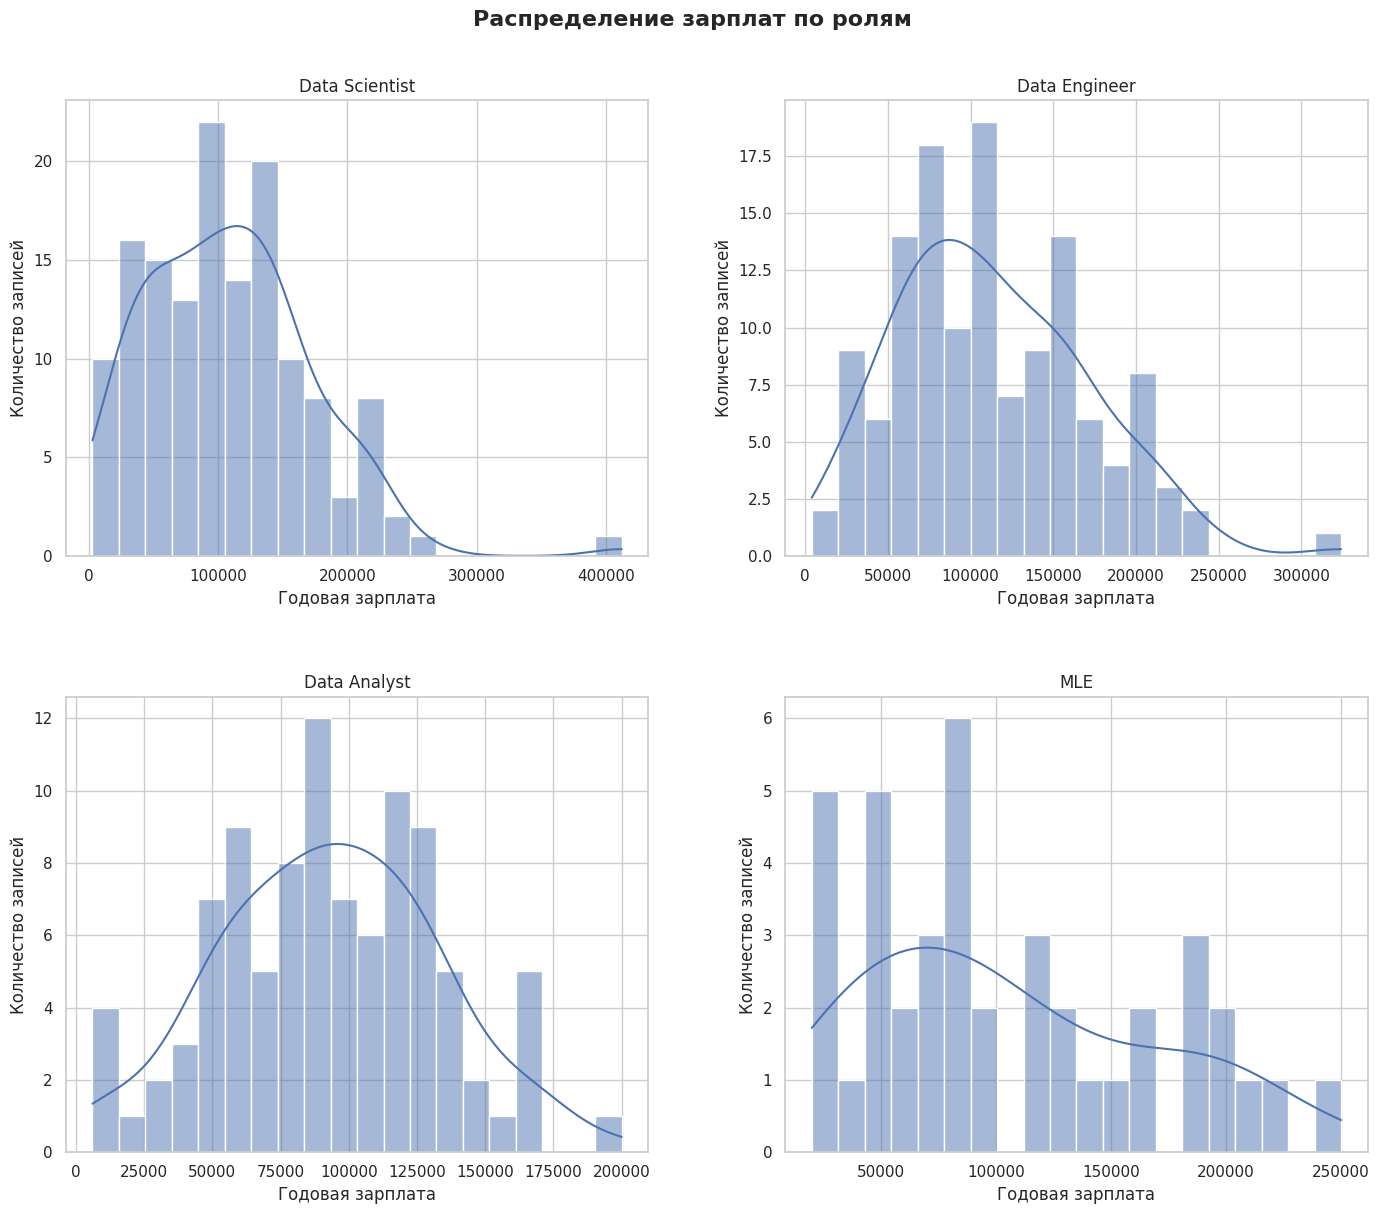

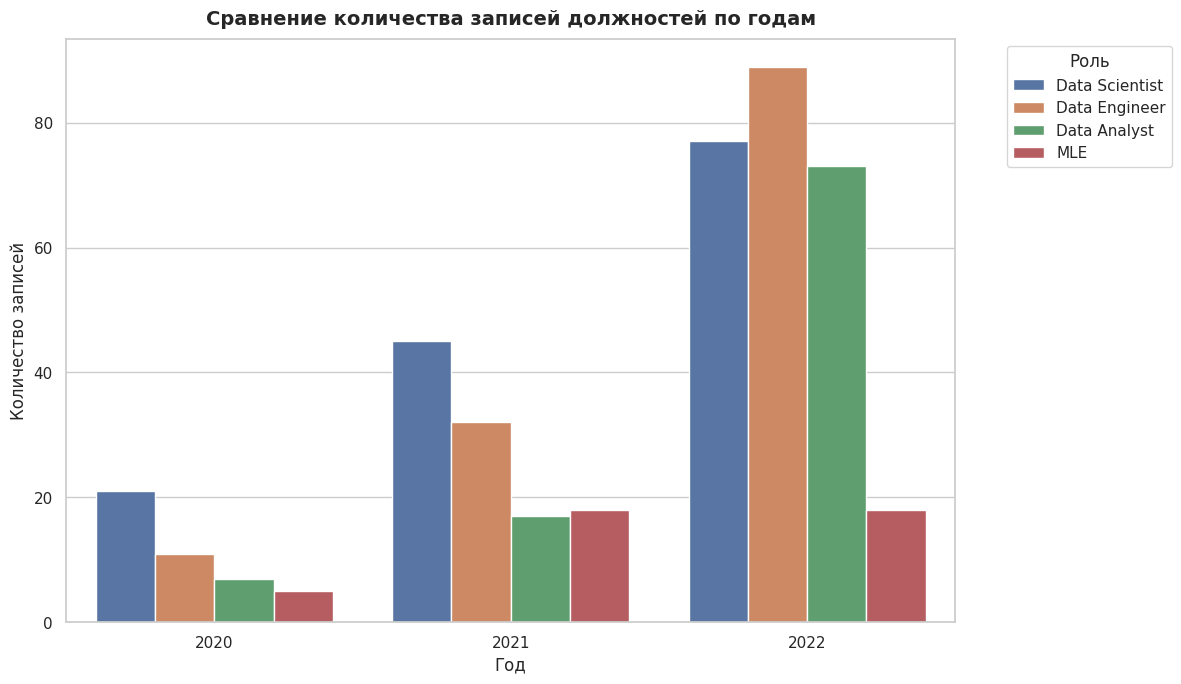

In [279]:
df_ds = df_work.loc[df_work['job_title'].eq('data scientist')].copy()
df_de = df_work.loc[df_work['job_title'].eq('data engineer')].copy()
df_da = df_work.loc[df_work['job_title'].eq('data analyst')].copy()
df_mle = df_work.loc[df_work['job_title'].eq('machine learning engineer')].copy()

# Собираем датафреймы для визуализации
dfs = {
    'Data Scientist': df_ds,
    'Data Engineer': df_de,
    'Data Analyst': df_da,
    'MLE': df_mle
}

# Таблица с данными по ЗП
salary_summary_all = pd.DataFrame({
    role: df['salary_in_usd'].agg(['count', 'median', 'mean', 'std', 'min', 'max'])
    for role, df in dfs.items()
})
print(salary_summary_all.map(format_with_commas))

# Графики ЗП для визуализации распределения
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Распределение зарплат по ролям', fontsize=16, fontweight='bold', y=1.01)
for idx, role in enumerate(dfs.keys()):
    row = idx // 2 
    col = idx % 2 
    ax = axes[row, col]
    sns.histplot( 
        data=dfs[role], 
        x='salary_in_usd', 
        bins=20, 
        kde=True, 
        ax=ax
    )
    ax.set(
        title=role, 
        xlabel='Годовая зарплата', 
        ylabel='Количество записей'
    )
plt.tight_layout(h_pad=4.0, w_pad=4.0)
plt.show()

# График количества записей по годям и ролям

# Соберём все уникальные годы, чтобы порядок был одинаковым на всех графиках 
all_years = sorted(pd.concat([df for df in dfs.values()])['work_year'].unique())

plot_data = []
for role, df in dfs.items():
    temp = df[['work_year']].copy()
    temp['role'] = role
    plot_data.append(temp)

plot_df = pd.concat(plot_data)

plt.figure(figsize=(12, 7))

sns.countplot(
    data=plot_df, 
    x='work_year', 
    hue='role', 
    order=all_years,
)

plt.title('Сравнение количества записей должностей по годам', fontsize=14, fontweight='bold', y=1.01)
plt.xlabel('Год')
plt.ylabel('Количество записей')
plt.legend(title='Роль', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

В принципе, если не придираться, распределение зарплат нормальное или лог-нормальное, кроме МЛЕ, но там и записей мало. Записи идут по  нарастающей общего количества с 20 по 22 год. Делать отдельные сравнительные анализы по годам видится бесперспективной затеей (но необходимой по условиям задачи), так как погодовая разница в предоставленных данных велика. Возможно сделать вывод о росте количества людей, занятых в сфере датасаенс (и около), но нет данных так ли это в реальности.

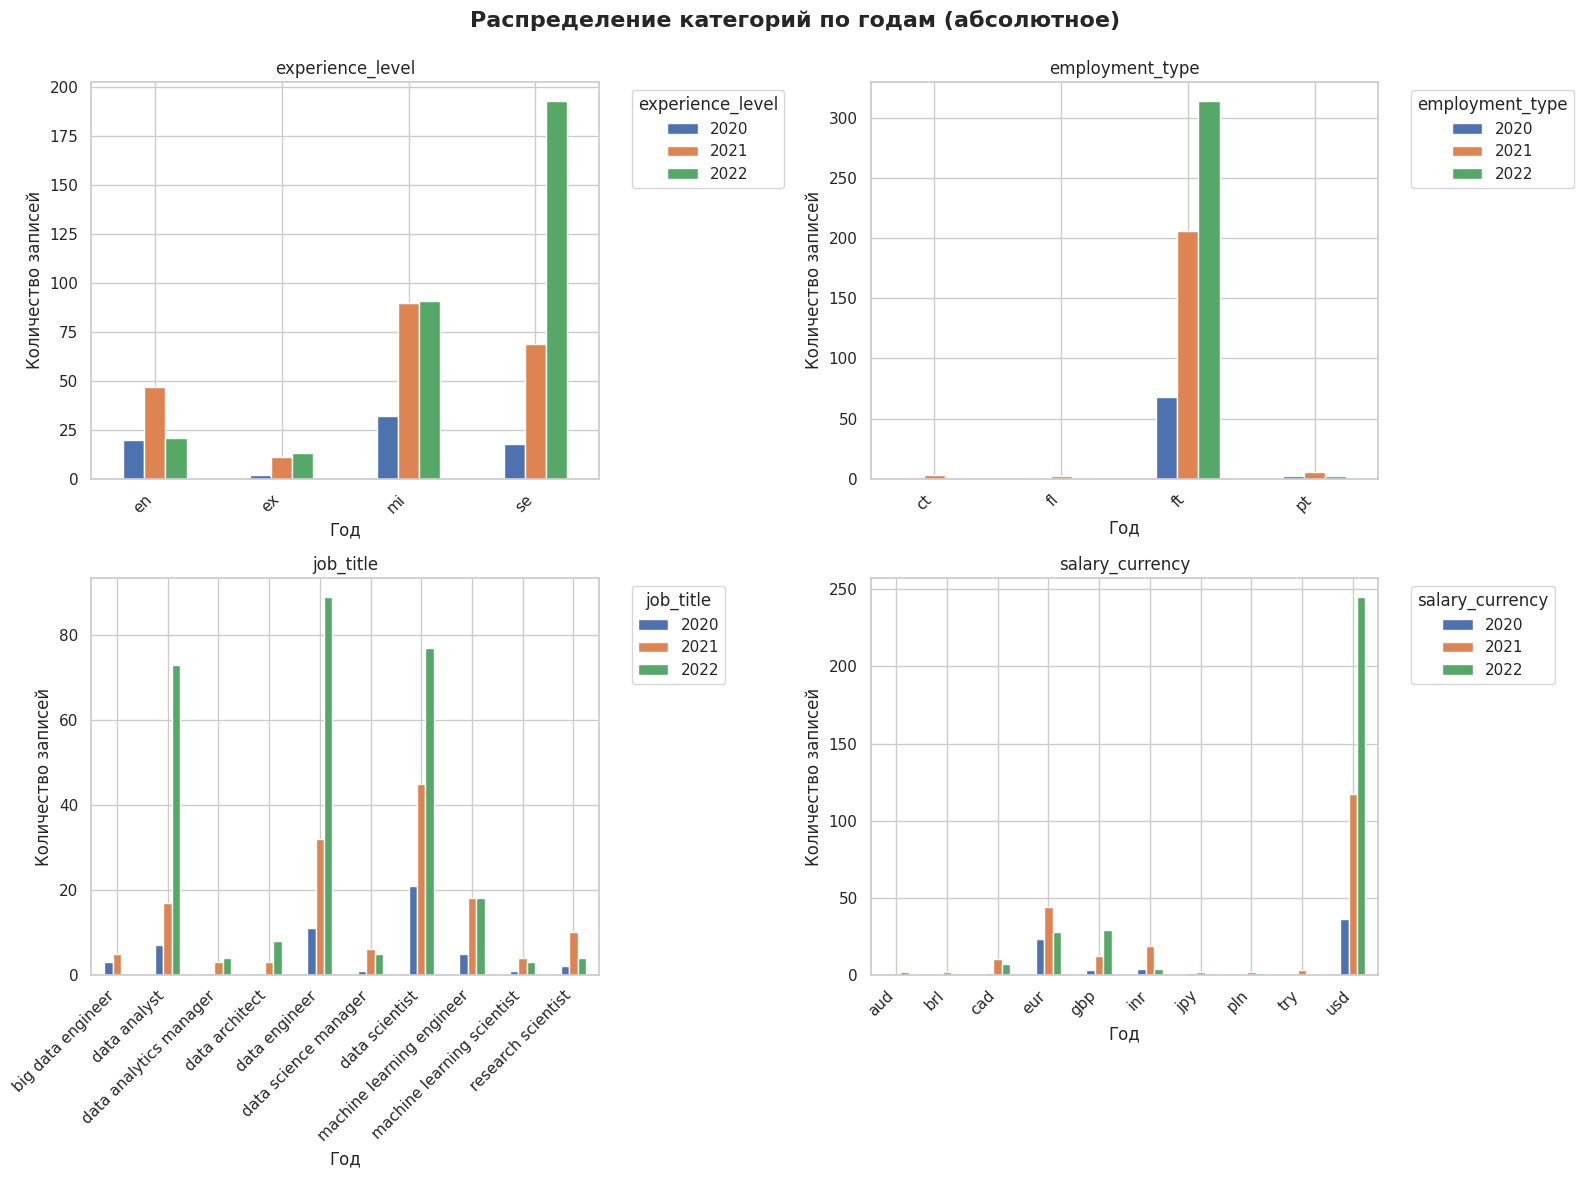

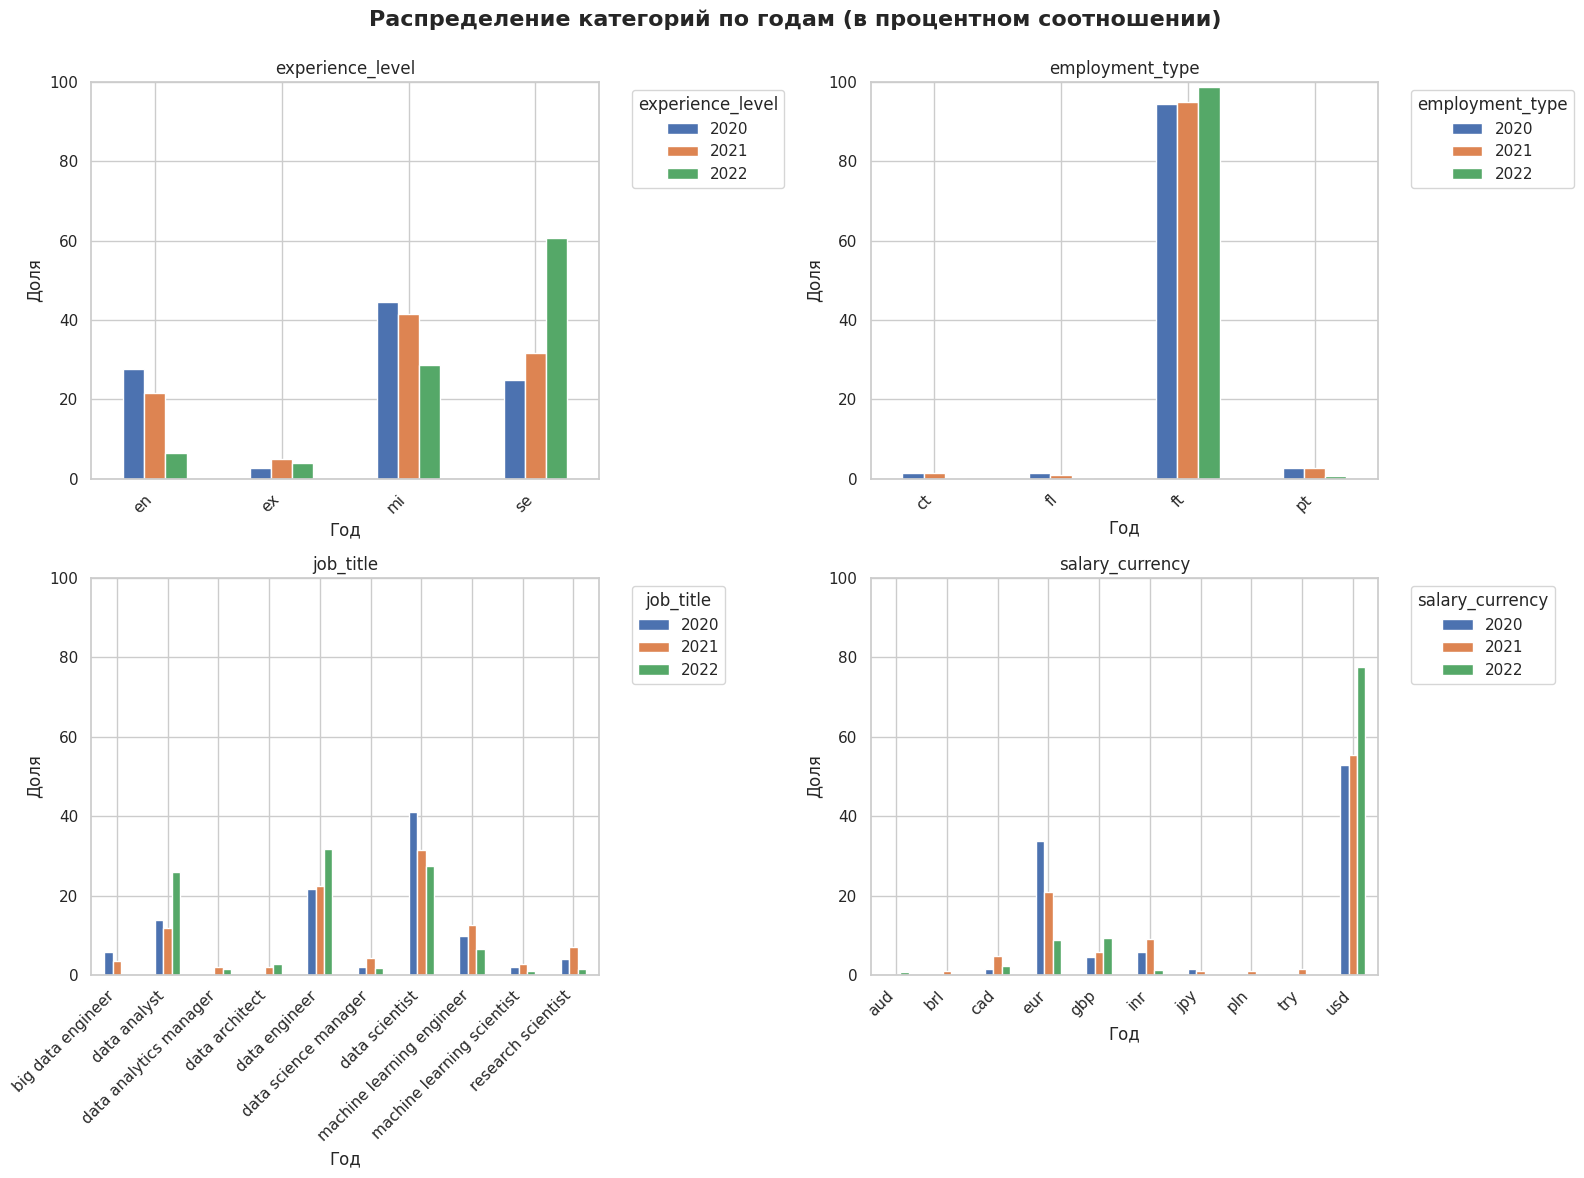

In [266]:
# Строим график в абсолютных величинах только для визуальной составляющей, 
# так как ранее было видно что разница между годовыми записями велика

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Распределение категорий по годам (абсолютное)', fontsize=16, fontweight='bold')

top_10 = {
    'job_title': df_work['job_title'].value_counts().head(10).index.tolist(),
    'salary_currency': df_work['salary_currency'].value_counts().head(10).index.tolist(),
}

for idx, (ax, column) in enumerate(zip(axes.flat, categorical_columns)):
    # 1. Строим кросс-таблицу: строки = категории, колонки = годы
    if column in top_10.keys():
        df_filtered = df_work[df_work[column].isin(top_10[column])]
        ct = pd.crosstab(df_filtered[column], df_filtered['work_year'])
    else:
        ct = pd.crosstab(df_work[column], df_work['work_year'])
    
    # 2. Гарантируем, что все графики имеют одинаковый порядок лет
    ct = ct.reindex(columns=all_years)
    
    # 3. Строим групповой бар-чарт
    ct.plot(kind='bar', 
            ax=ax,
            # color=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2'],  # свои цвета
            # edgecolor='black'
    )
    
    ax.set(title=f'{column}', 
           xlabel='Год', 
           ylabel='Количество записей')
    
    # Поворачиваем подписи лет, чтобы не налезали
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    # Легенда справа
    ax.legend(title=column, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.subplots_adjust(top=0.92)  # Отступ для общего заголовка
plt.show()



# А вот график процентного соотношения может нам что-то дать
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Распределение категорий по годам (в процентном соотношении)', fontsize=16, fontweight='bold')

for idx, (ax, column) in enumerate(zip(axes.flat, categorical_columns)):
    if column in top_10.keys():
        df_filtered = df_work[df_work[column].isin(top_10[column])]
        ct = pd.crosstab(df_filtered[column], df_filtered['work_year'])
    else:
        ct = pd.crosstab(df_work[column], df_work['work_year'])
    
    ct = ct.reindex(columns=all_years)
    
    # Нормализуем: делим каждый столбец на его сумму
    ct_norm = ct.div(ct.sum(axis=0), axis=1) * 100
    
    ct_norm.plot(
        kind='bar', 
        ax=ax, 
        # color=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2'], 
        # edgecolor='black'
    )
    ax.set(title=f'{column}', xlabel='Год', ylabel='Доля')
    ax.set_ylim(0, 100)    

    # Поворачиваем подписи лет, чтобы не налезали
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    # Легенда справа
    ax.legend(title=column, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.subplots_adjust(top=0.92)  # Отступ для общего заголовка
plt.show()

В процентном соотношении за изучаемый период резко сократилось количество джунов и миддлов, а количество сеньоров, наоборот увеличилось, причём скачок был в 2022 году. Занятость стремится в сторону увеличения фуллтайм сотрудников. Количество датасаентистов сократилось, а вот количество дата аналитиков и дата инженеров, наоборот увеличилось. По остальным профессиям данных маловато, но прослеживается некий тренд на уменьшение их количества. По валютным выплатам в 22 году резко увеличилось количество выплат в долларах США, так же показывают рост выплаты в британских фунтах, тогда как выплаты в остальных валютах сокращаются. Имеется в виду количество выплат, а не величина зарплат как таковых.

Удовлетворили любопытство, далее будем работать только с **Data Scientist**, так как в основном задачи у нас по этой профессии. Датасет df_ds

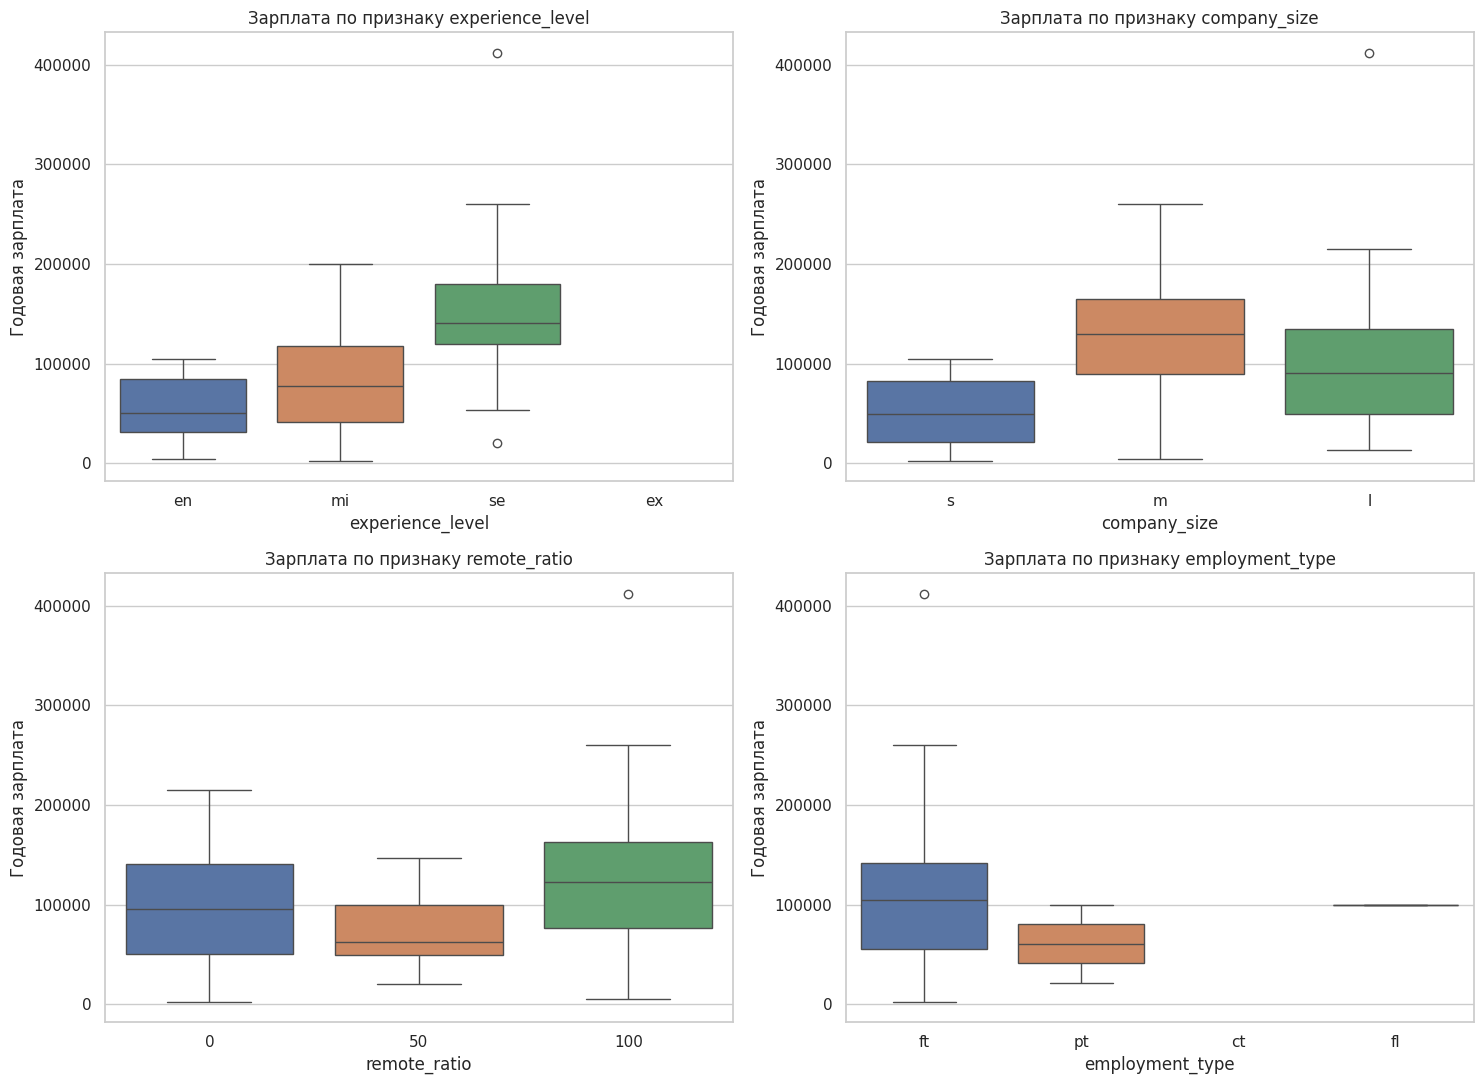

Число наблюдений в каждой группе:


,Количество
experience_level,
se,61
mi,60
en,22
ex,0


,Количество
company_size,
m,77
l,45
s,21


,Количество
remote_ratio,
100,79
0,39
50,25


,Количество
employment_type,
ft,140
pt,2
fl,1
ct,0


In [267]:
# Построим  графики зарплаты исходя из этих факторов, чтобы визуально оценить различия и распределения
salary_factors = [
    ('experience_level', ['en', 'mi', 'se', 'ex']),
    ('company_size', ['s', 'm', 'l']),
    ('remote_ratio', [0, 50, 100]),
    ('employment_type', ['ft', 'pt', 'ct', 'fl']),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (column, order) in zip(axes.flat, salary_factors):
    sns.boxplot(
        data=df_ds,
        x=column,
        y='salary_in_usd',
        order=order,
        hue=column,
        hue_order=order,
        dodge=False,
        legend=False,
        ax=ax,
    )
    ax.set(
        title=f'Зарплата по признаку {column}', 
        xlabel=column, 
        ylabel='Годовая зарплата'
    )
plt.tight_layout()
plt.show()

print('Число наблюдений в каждой группе:')
for column, _ in salary_factors:
    display(df_ds[column].value_counts(dropna=False).rename('Количество').to_frame())

Первичные наблюдения:
- **уровень опыта**: зарплата растёт при росте опыта сотрудника.
- **размер компании**: зарплаты выше в средних компаниях. Так как распределения широкие, это, скореее, визуальная тенденция, а не доказательство влияния.
- **формат работы**: у удалёнщиков визуально зарплата выше, но по одному графику нельзя заключить, что различия статистически значимы.
- **тип занятости**: большинство наблюдений относятся к полной занятости, выводы о сравнении этих типов безосновательны

### Проверка гипотез и ответы на вопросы

Во всех тестах использую уровень значимости **α = 0,05**. Для зарплат проверяю нормальность групп по критерию Шапиро—Уилка и равенство дисперсий по критерию Левена. Зарплатные распределения асимметричны, по-этому для сравнения буду использовать ранговые методы (Манн—Уитн и Краскел—Уоллис). Параметрические t-тесты и/или ANOVA считаю неприемлемыми, так как нужна нормальность и равенство дисперсий, чего в наших данных не наблюдается. Проверки Шапиро и Левена использую как диагностику.

Для каждой гипотезы формулирую H0 и H1. Парные сравнения после общего теста буду корректировать по методу Холма.

#### Ежегодный рост зарплат Data Scientist

**H0:** связь между годом и зарплатой отсутствует, распределения зарплат по годам не различаются  
**H1:** зарплаты имеют положительный тренд по годам

Для общего сравнения всех периодов использую метод Краскела—Уоллиса, для монотонного тренда - корреляцию Спирмена. Парные сравнения Манна—Уитни с поправкой Холма покажут, в какие именно годы обнаружены различия

,Год,n,Медиана,p Шапиро—Уилка
0,2020,21,62726.0,0.000002
1,2021,45,73000.0,0.124583
2,2022,77,140000.0,0.326895


Левен: W=0.1837978321, p=0.8323044695
Краскел—Уоллис: H=41.8473809443, p=0.0000000008
Спирмен: rho=0.5130422968, p=0.0000000001


,Сравнение,p,p с поправкой Холма
0,2020 — 2021,0.6397163738,0.6397163738
1,2020 — 2022,0.0000196019,0.0000392038
2,2021 — 2022,0.0000000050,0.0000000150


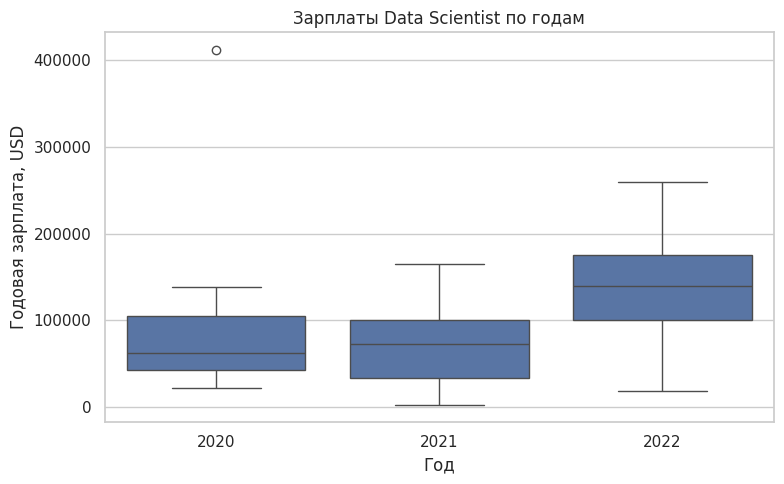

In [268]:
year_groups = {
    year: group['salary_in_usd'].to_numpy()
    for year, group in df_ds.groupby('work_year')
}

normality_by_year = pd.DataFrame([
    {
        'Год': year,
        'n': len(values),
        'Медиана': np.median(values),
        'p Шапиро—Уилка': stats.shapiro(values).pvalue,
    }
    for year, values in year_groups.items()
])
display(normality_by_year)

levene_years = stats.levene(*year_groups.values(), center='median')
kruskal_years = stats.kruskal(*year_groups.values())
spearman_trend = stats.spearmanr(df_ds['work_year'], df_ds['salary_in_usd'])
# Здесь и далее для значений использую .10f для единообразия, так как некоторые  достаточно мелкие 
# чтобы уходить в экспоненту
print(f'Левен: W={levene_years.statistic:.10f}, p={levene_years.pvalue:.10f}')
print(f'Краскел—Уоллис: H={kruskal_years.statistic:.10f}, p={kruskal_years.pvalue:.10f}')
print(f'Спирмен: rho={spearman_trend.statistic:.10f}, p={spearman_trend.pvalue:.10f}')

pairwise_years = []
years = sorted(year_groups)
for i, year_a in enumerate(years):
    for year_b in years[i + 1:]:
        result = stats.mannwhitneyu(year_groups[year_a], year_groups[year_b], alternative='two-sided')
        pairwise_years.append({'Сравнение': f'{year_a} — {year_b}', 'p': f'{result.pvalue:.10f}'})
pairwise_years = pd.DataFrame(pairwise_years)
pairwise_years['p с поправкой Холма'] = multipletests(pairwise_years['p'].astype(float), method='holm')[1]
pairwise_years['p с поправкой Холма'] = pairwise_years['p с поправкой Холма'].apply(lambda x: f'{x:.10f}')
display(pairwise_years)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_ds, x='work_year', y='salary_in_usd', order=years, ax=ax)
ax.set(title='Зарплаты Data Scientist по годам', xlabel='Год', ylabel='Годовая зарплата, USD')
plt.tight_layout()
plt.show()

*Промежуточный вывод.* Медианная зарплата растёт с 62_726 в 2020 году до 73_000 в 2021-м и 140_000 в 2022. Тренд положительный (rho ~ 0,513 при p < 0,001). Однако сравнение 2020 и 2021 годов после поправки Холма незначимо. Статистически подтверждён скачок в 2022, но не динамичный рост в каждом отдельном году. Это наблюдаемая динамика выборки, не скорректированная на инфляцию, изменение состава специалистов, либо их дефицит на рынке труда.

#### Data Scientist и Data Engineer в 2022 году

**H0:** распределения зарплат двух должностей в 2022 году одинаковы.  
**H1:** распределения различаются. 

Использую двусторонний критерий Манна—Уитни.

,count,median,mean,std
job_title,,,,
data engineer,89,120000.0,126375.696629,55954.398677
data scientist,77,140000.0,136172.090909,54563.084740


Шапиро—Уилк, Data Scientist: p=0.3268949541
Шапиро—Уилк, Data Engineer: p=0.0099886838
Левен: p=0.6030672438
Манн—Уитни: U=3866.5000000000, p=0.1546491782, rank-biserial r=0.1284109149


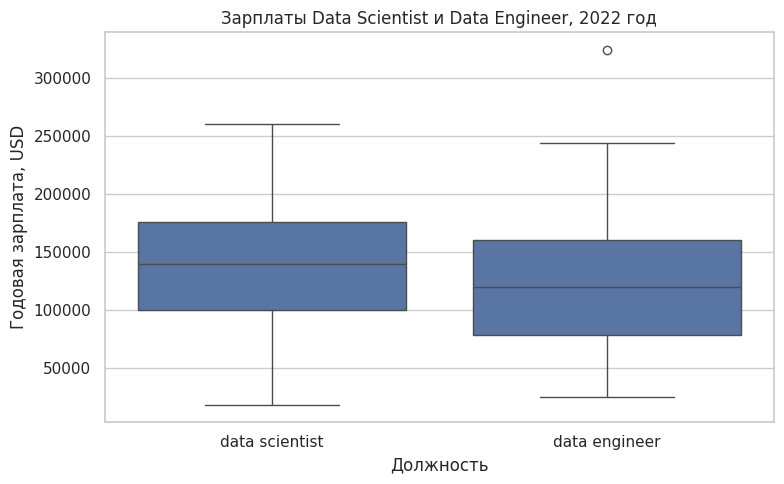

In [269]:
roles_2022 = df_work.loc[
    df_work['work_year'].eq(2022)
    & df_work['job_title'].isin(['data scientist', 'data engineer'])
]
ds_2022 = roles_2022.loc[roles_2022['job_title'].eq('data scientist'), 'salary_in_usd']
de_2022 = roles_2022.loc[roles_2022['job_title'].eq('data engineer'), 'salary_in_usd']

salary_by_role_2022 = roles_2022.groupby('job_title', observed=True)['salary_in_usd'].agg(
    ['count', 'median', 'mean', 'std']
)
display(salary_by_role_2022)
print('Шапиро—Уилк, Data Scientist:', f'p={stats.shapiro(ds_2022).pvalue:.10f}')
print('Шапиро—Уилк, Data Engineer:', f'p={stats.shapiro(de_2022).pvalue:.10f}')
levene_roles = stats.levene(ds_2022, de_2022, center='median')
role_test = stats.mannwhitneyu(ds_2022, de_2022, alternative='two-sided')
rank_biserial = 2 * role_test.statistic / (len(ds_2022) * len(de_2022)) - 1
print(f'Левен: p={levene_roles.pvalue:.10f}')
print(f'Манн—Уитни: U={role_test.statistic:.10f}, p={role_test.pvalue:.10f}, rank-biserial r={rank_biserial:.10f}')


fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=roles_2022[roles_2022['job_title'].isin(['data scientist', 'data engineer'])],
    x='job_title', 
    y='salary_in_usd', 
    order=['data scientist', 'data engineer'],
    ax=ax
)
ax.set(
    title='Зарплаты Data Scientist и Data Engineer, 2022 год', 
    xlabel='Должность', 
    ylabel='Годовая зарплата, USD'
)
plt.tight_layout()
plt.show()

**Вывод:** медиана Data Scientist - 140_000, Data Engineer - 120_000. Различие распределений статистически не подтверждено (Манн—Уитни p ~ 0,155). Более высокая медиана Data Scientist в этой выборке сама по себе не доказывает, что зарплаты этой должности выше в совокупности.

#### Зарплата Data Scientist в компаниях разных размеров

**H0:** зарплатные распределения в компаниях среднего (M) и крупного (L) размера в 2022 году одинаковы.  
**H1:** они различаются. 

Для сравнения M и L использую критейрий Манна—Уитни. В категории S в 2022 году только одна запись, поэтому её показываем на графике и в таблице, но не включаем в вывод о различии групп.

,count,median,mean,std
company_size,,,,
s,1,48000.0,48000.000000,NaN
m,62,140000.0,139442.000000,51264.526672
l,14,137700.0,127989.071429,65969.711689


Шапиро—Уилк, M: p=0.8028402607
Шапиро—Уилк, L: p=0.1203037938
Левен: p=0.2539786921
Манн—Уитни (M <=> L): U=463.0, p=0.7024183819


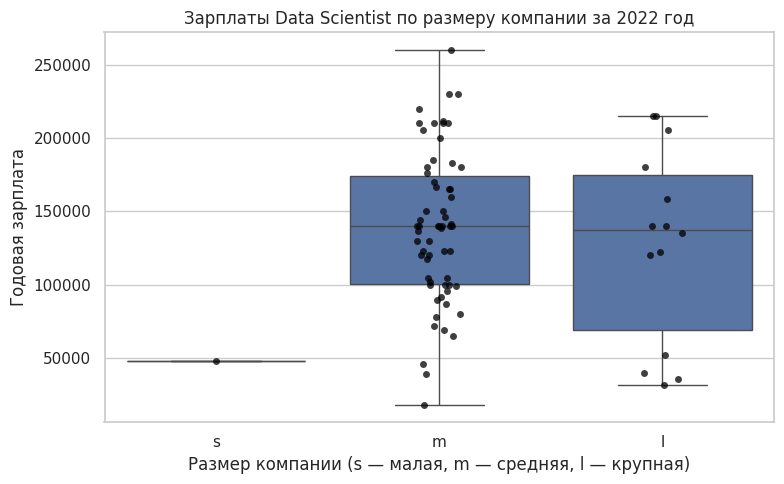

In [270]:
ds_size_2022 = df_ds.loc[df_ds['work_year'].eq(2022)]
size_summary_2022 = ds_size_2022.groupby('company_size', observed=True)['salary_in_usd'].agg(
    ['count', 'median', 'mean', 'std']
).reindex(['s', 'm', 'l'])
display(size_summary_2022)

medium = ds_size_2022.loc[ds_size_2022['company_size'].eq('m'), 'salary_in_usd']
large = ds_size_2022.loc[ds_size_2022['company_size'].eq('l'), 'salary_in_usd']
print('Шапиро—Уилк, M:', f'p={stats.shapiro(medium).pvalue:.10f}')
print('Шапиро—Уилк, L:', f'p={stats.shapiro(large).pvalue:.10f}')
levene_size = stats.levene(medium, large, center='median')
size_test = stats.mannwhitneyu(medium, large, alternative='two-sided')
print(f'Левен: p={levene_size.pvalue:.10f}')
print(f'Манн—Уитни (M <=> L): U={size_test.statistic:.1f}, p={size_test.pvalue:.10f}')

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=ds_size_2022, 
    x='company_size', 
    y='salary_in_usd', 
    order=['s', 'm', 'l'], 
    ax=ax
)
sns.stripplot(
    data=ds_size_2022, 
    x='company_size', 
    y='salary_in_usd', 
    order=['s', 'm', 'l'], 
    color='black', 
    alpha=0.75, 
    ax=ax
)
ax.set(
    title='Зарплаты Data Scientist по размеру компании за 2022 год', 
    xlabel='Размер компании (s — малая, m — средняя, l — крупная)', 
    ylabel='Годовая зарплата'
)
plt.tight_layout()
plt.show()

**Вывод:** медианы зарплат для средних и больших компаний близки (140_000 и 137_700), статистически значимого различия не выявлено (p ~ 0,702). Отсутствие значимости между средними и большими компаниями не доказывает полного равенства зарплат.

#### Связь между наличием должности Data Scientist / Data Engineer и размером компании

**H0:** должность (Data Scientist или Data Engineer) независима от размера компании.  
**H1:** распределение должностей зависит от размера компании.

Использую критерий хи-квадрат Пирсона, проверяю ожидаемые частоты. Силу связи рассчитаю по V Крамера.

company_size,s,m,l
job_title,,,
data scientist,21,77,45
data engineer,6,89,37


company_size,s,m,l
Должность,,,
data scientist,77.8,46.4,54.9
data engineer,22.2,53.6,45.1


Минимальная ожидаемая частота: 12.9600000000
Хи-квадрат Пирсона: chi2=9.5565815482, deg_frdm=2, p=0.0084103619, V Крамера=0.1864167525


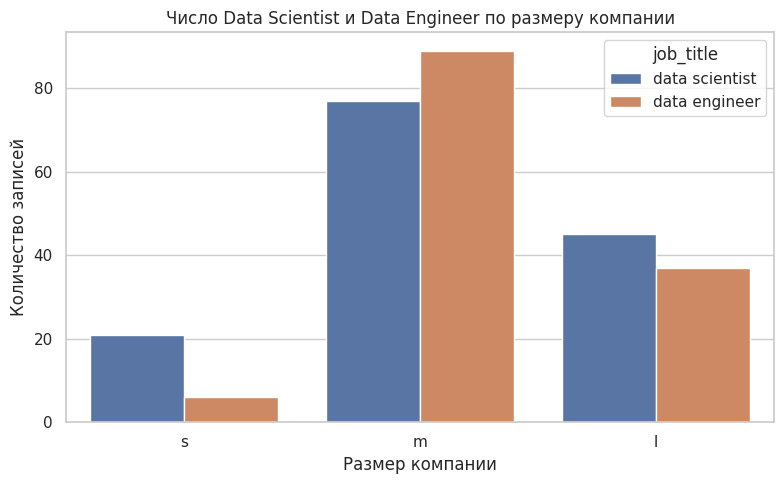

In [280]:
ds_de = df_work.loc[df_work['job_title'].isin(['data scientist', 'data engineer'])]
role_size_table = pd.crosstab(ds_de['job_title'], ds_de['company_size']).reindex(
    index=['data scientist', 'data engineer'], columns=['s', 'm', 'l'], fill_value=0
)
display(role_size_table)
display((role_size_table.div(role_size_table.sum(axis=0), axis=1) * 100).round(1).rename_axis('Должность'))

chi2, chi2_p, degrees_freedom, expected = stats.chi2_contingency(role_size_table, correction=False)
cramers_v = np.sqrt(chi2 / (role_size_table.to_numpy().sum() * min(role_size_table.shape[0] - 1, role_size_table.shape[1] - 1)))
print(f'Минимальная ожидаемая частота: {expected.min():.10f}')
print(f'Хи-квадрат Пирсона: chi2={chi2:.10f}, deg_frdm={degrees_freedom}, p={chi2_p:.10f}, V Крамера={cramers_v:.10f}')

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=ds_de, 
    x='company_size', 
    hue='job_title', 
    hue_order=['data scientist', 'data engineer'],
    order=['s', 'm', 'l'], 
    ax=ax
)
ax.set(
    title='Число Data Scientist и Data Engineer по размеру компании', 
    xlabel='Размер компании', 
    ylabel='Количество записей'
)
plt.tight_layout()
plt.show()

**Вывод:** Связь между должностью и размером компании статистически значима (p ~ 0,008), но слаба по величине V Крамера ~ 0,186. В выборке Data Scientist относительно чаще встречаются в малых компаниях, а Data Engineer — в средних. Это корреляция в наблюдаемых данных, а не доказательство влияния размера компании.

#### Превышает ли зарплата Data Scientist в США ориентир 100_000?

Это дополнительная проверка относительно явно заданного бизнес-ориентира. Выбираем Data Scientist с локацией компании в США за 2022 год.

**H0:** вероятность получить зарплату выше 100_000 не превышает 0,5, т.е. медиана не выше ориентира.  
**H1:** вероятность превышения больше 0,5, т.е. медиана выше ориентира.

Использую точный одновыборочный знаковый тест, наблюдения ровно на пороге исключаются из подсчёта знаков.

In [272]:
salary_threshold = 100_000
us_ds_2022 = df_work.loc[
    df_work['job_title'].eq('data scientist')
    & df_work['work_year'].eq(2022)
    & df_work['company_location'].eq('us'),
    'salary_in_usd',
]
above = int((us_ds_2022 > salary_threshold).sum())
below = int((us_ds_2022 < salary_threshold).sum())
tied = int((us_ds_2022 == salary_threshold).sum())

sign_test = stats.binomtest(above, above + below, p=0.5, alternative='greater')
print(f'n={len(us_ds_2022)}, медиана={us_ds_2022.median():,.0f}')
print(f'Выше ориентира: {above}, ниже: {below}, ровно на пороге: {tied}')
print(f'Одновыборочный знаковый тест: p={sign_test.pvalue:.10f}')

n=60, медиана=140,850
Выше ориентира: 52, ниже: 6, ровно на пороге: 2
Одновыборочный знаковый тест: p=0.0000000002


**Вывод:** в выборке Data Scientist из компаний США за 2022 год медиана выше выбранного ориентира 100_000, знаковый тест подтверждает превышение (p < 0,001)

### Дополнительные бизнес-гипотезы

#### Уровень опыта связан с зарплатой Data Scientist

**H0:** зарплатные распределения одинаковы для уровней EN, MI и SE в 2022 году.  
**H1:** как минимум для одного уровня распределение отличается.

Использую Краскела—Уоллиса, затем парные тесты Манна—Уитни с поправкой Холма. Уровень EX в 2022 году не представлен.

,count,median,mean
experience_level,,,
en,5,52396.0,59508.200000
mi,22,95807.0,99573.590909
se,50,148000.0,159941.820000


,Уровень,n,p Шапиро—Уилка
0,en,5,0.7619207000
1,mi,22,0.4942412921
2,se,50,0.0877524796


Левен: p=0.5623
Краскел—Уоллис: H=28.385, p=6.859e-07


,Сравнение,p,p с поправкой Холма
0,en — mi,0.1045073744,0.1045073744
1,en — se,0.0004361648,0.0008723296
2,mi — se,0.0000087520,0.0000262560


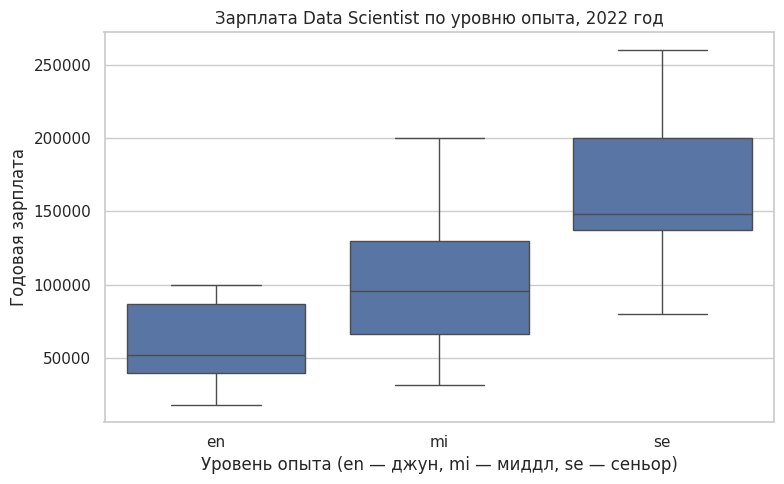

In [273]:
ds_experience_2022 = df_ds.loc[df_ds['work_year'].eq(2022)]
experience_groups = {
    level: group['salary_in_usd'].to_numpy()
    for level, group in ds_experience_2022.groupby('experience_level', observed=True)
}
experience_summary = ds_experience_2022.groupby('experience_level', observed=True)['salary_in_usd'].agg(
    ['count', 'median', 'mean']
).reindex(['en', 'mi', 'se'])
display(experience_summary)

normality_experience = pd.DataFrame([
    {'Уровень': level, 'n': len(values), 'p Шапиро—Уилка': f"{stats.shapiro(values).pvalue:.10f}"}
    for level, values in experience_groups.items()
])
display(normality_experience)
levene_experience = stats.levene(*experience_groups.values(), center='median')
experience_test = stats.kruskal(*experience_groups.values())
print(f'Левен: p={levene_experience.pvalue:.4g}')
print(f'Краскел—Уоллис: H={experience_test.statistic:.3f}, p={experience_test.pvalue:.4g}')

experience_pairs = []
levels = list(experience_groups)
for i, level_a in enumerate(levels):
    for level_b in levels[i + 1:]:
        result = stats.mannwhitneyu(experience_groups[level_a], experience_groups[level_b], alternative='two-sided')
        experience_pairs.append({'Сравнение': f'{level_a} — {level_b}', 'p': f"{result.pvalue:.10f}"})
experience_pairs = pd.DataFrame(experience_pairs)
experience_pairs['p с поправкой Холма'] = multipletests(experience_pairs['p'].astype(float), method='holm')[1]
experience_pairs['p с поправкой Холма'] = experience_pairs['p с поправкой Холма'].apply(lambda x: f"{x:.10f}")
display(experience_pairs)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=ds_experience_2022, 
    x='experience_level', 
    y='salary_in_usd', 
    order=['en', 'mi', 'se'], 
    ax=ax
)
ax.set(
    title='Зарплата Data Scientist по уровню опыта, 2022 год', 
    xlabel='Уровень опыта (en — джун, mi — миддл, se — сеньор)', 
    ylabel='Годовая зарплата'
)
plt.tight_layout()
plt.show()

**Вывод:** уровень опыта связан с зарплатой (Краскел—Уоллис: p < 0,001): медиана увеличивается от 52_396 для джуна до 95_807 для мидла и 148_000 для сеньора. После поправки Холма различия между джуном и мидлом незначимы, а сравнения с сеньором значимы. Уровень опыта - сильный фактор ассоциации в данных, причинность тест не устанавливает.

#### Различается ли зарплата при полностью удалённой работе?

**H0:** зарплатные распределения Data Scientist с remote_ratio 0 и 100 в 2022 году одинаковы.  
**H1:** они различаются.

Использую двусторонний тест Манна—Уитни. Группа remote_ratio = 50 содержит только две записи, поэтому остаётся в визуализации, но не используется в тесте.

,count,median,mean
remote_ratio,,,
0,25,122346.0,126328.76
50,2,93351.5,93351.50
100,50,140000.0,142806.58


Шапиро—Уилк, remote_ratio=0: p=0.6315
Шапиро—Уилк, remote_ratio=100: p=0.2119
Левен: p=0.6496
Манна—Уитни (0 против 100): U=506.0, p=0.1827


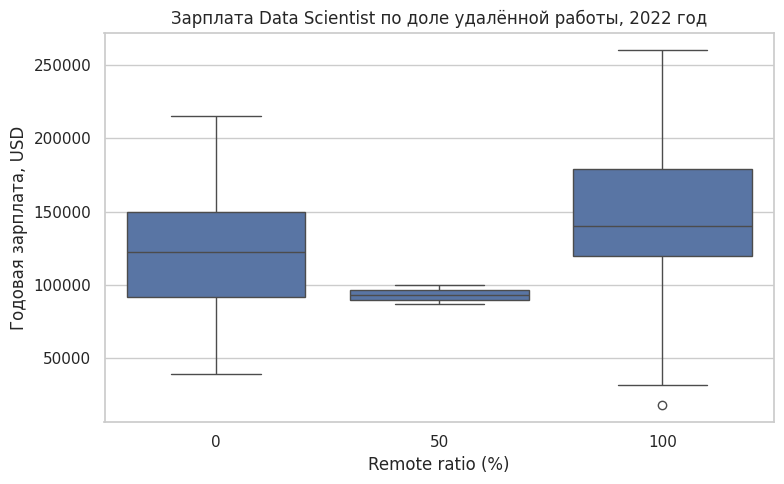

In [274]:
ds_remote_2022 = df_ds.loc[df_ds['work_year'].eq(2022)]
remote_summary = ds_remote_2022.groupby('remote_ratio', observed=True)['salary_in_usd'].agg(
    ['count', 'median', 'mean']
).reindex([0, 50, 100])
display(remote_summary)

onsite = ds_remote_2022.loc[ds_remote_2022['remote_ratio'].eq(0), 'salary_in_usd']
fully_remote = ds_remote_2022.loc[ds_remote_2022['remote_ratio'].eq(100), 'salary_in_usd']
print('Шапиро—Уилк, remote_ratio=0:', f'p={stats.shapiro(onsite).pvalue:.4g}')
print('Шапиро—Уилк, remote_ratio=100:', f'p={stats.shapiro(fully_remote).pvalue:.4g}')
levene_remote = stats.levene(onsite, fully_remote, center='median')
remote_test = stats.mannwhitneyu(onsite, fully_remote, alternative='two-sided')
print(f'Левен: p={levene_remote.pvalue:.4g}')
print(f'Манна—Уитни (0 против 100): U={remote_test.statistic:.1f}, p={remote_test.pvalue:.4g}')

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=ds_remote_2022, x='remote_ratio', y='salary_in_usd', order=[0, 50, 100], ax=ax)
ax.set(title='Зарплата Data Scientist по доле удалённой работы, 2022 год', xlabel='Remote ratio (%)', ylabel='Годовая зарплата, USD')
plt.tight_layout()
plt.show()

**Вывод:** медианы равны 122_346 для офисных сотрудников (0) и 140_000 для удалёнщиков (100), однако различие статистически незначимо (p ~ 0,183). Данных недостаточно, чтобы утверждать, что зарплата связана с форматом работы.

### Проверка устойчивости к точным совпадениям записей

Поскольку дубликаты в данных всё-таки есть, хотя и нельзя точно утверждать,  что это дубликаты, а не совпадения, сравним ключевые p-значения для полной базы и базы после удаления дубликатов. Для очистки совести и исключения вляния дублирующихся записей.

In [281]:
def key_test_pvalues(data):
    ds = data.loc[data['job_title'].eq('data scientist')]
    ds22 = ds.loc[ds['work_year'].eq(2022)]
    roles22 = data.loc[
        data['work_year'].eq(2022)
        & data['job_title'].isin(['data scientist', 'data engineer'])
    ]
    role_groups = [
        roles22.loc[roles22['job_title'].eq(role), 'salary_in_usd']
        for role in ['data scientist', 'data engineer']
    ]
    size_groups = [
        ds22.loc[ds22['company_size'].eq(size), 'salary_in_usd']
        for size in ['m', 'l']
    ]
    experience_groups = [
        group['salary_in_usd']
        for _, group in ds22.groupby('experience_level', observed=True)
    ]
    remote_groups = [
        ds22.loc[ds22['remote_ratio'].eq(ratio), 'salary_in_usd']
        for ratio in [0, 100]
    ]
    contingency = pd.crosstab(
        data.loc[data['job_title'].isin(['data scientist', 'data engineer']), 'job_title'],
        data.loc[data['job_title'].isin(['data scientist', 'data engineer']), 'company_size'],
    )
    us_salary = data.loc[
        data['job_title'].eq('data scientist')
        & data['work_year'].eq(2022)
        & data['company_location'].eq('us'),
        'salary_in_usd',
    ]
    above = int((us_salary > salary_threshold).sum())
    below = int((us_salary < salary_threshold).sum())

    return {
        'Тренд по годам (Спирмен)': stats.spearmanr(ds['work_year'], ds['salary_in_usd']).pvalue,
        'data scientist против data engineer': stats.mannwhitneyu(*role_groups).pvalue,
        'Размер компании m против l': stats.mannwhitneyu(*size_groups).pvalue,
        'Опыт (Краскел—Уоллис)': stats.kruskal(*experience_groups).pvalue,
        'Удалённая работа 0 против 100': stats.mannwhitneyu(*remote_groups).pvalue,
        'Должность и размер (хи-квадрат)': stats.chi2_contingency(contingency, correction=False).pvalue,
        'Одновыборочный знаковый тест': stats.binomtest(above, above + below, p=0.5, alternative='greater').pvalue,
    }

sensitivity = pd.DataFrame({
'Все наблюдения': key_test_pvalues(df_work),
'Без точных совпадений': key_test_pvalues(df_work.drop_duplicates()),
})
sensitivity[f'Решение при alpha={P_VALUE_THRESHOLD}, все данные'] = sensitivity['Все наблюдения'] < P_VALUE_THRESHOLD
sensitivity[f'Решение при alpha={P_VALUE_THRESHOLD}, без совпадений'] = sensitivity['Без точных совпадений'] < P_VALUE_THRESHOLD
display(sensitivity.style.format({
    'Все наблюдения': '{:.10f}',
    'Без точных совпадений': '{:.10f}',
}))

,Все наблюдения,Без точных совпадений,"Решение при alpha=0.05, все данные","Решение при alpha=0.05, без совпадений"
Тренд по годам (Спирмен),0.0000000001,0.0000000183,True,True
data scientist против data engineer,0.1546491782,0.3194108313,False,False
Размер компании m против l,0.7024183819,0.8477964259,False,False
Опыт (Краскел—Уоллис),0.0000006859,0.0000041788,True,True
Удалённая работа 0 против 100,0.1827183795,0.3687253391,False,False
Должность и размер (хи-квадрат),0.0084103619,0.0049745976,True,True
Одновыборочный знаковый тест,0.0000000002,0.0000001551,True,True


Ключевые параметры  неизменяются при дедупликации.

### Итоговые выводы

**Годовая динамика:** зарплаты Data Scientist заметно выше в 2022 году, чем в 2020–2021 годах. Положительный тренд подтверждён, рост с 2020 до 2021 года отдельно статистически не подтверждён. Инфляция и состояние ранка труда не контролировались.

**Data Scientist и Data Engineer:** в 2022 году медиана Data Scientist выше (140_000 против 120_000), но статистически значимого различия не выявлено.

**Размер компании:** медианы в средних и крупных компаниях в 2022 году практически совпадают, различие незначимо. Для малого бизнеса есть только одна запись, обобщение невозможно.

**Должность и размер компании:** обнаружена статистически значимая, но слабая связь между ролями Data Scientist / Data Engineer и размером компании.

**Дополнительные факторы:** зарплата связаны с уровнем опыта, опытных сотрудники получают более высокую зарпалату. Для формы работы в 2022 году статистически значимого различия между полностью удалённой и офисной работой не обнаружено.

**Одновыборочная проверка:** у Data Scientist из США в 2022 году зарплата статистически чаще превышает выбранный ориентир 100_000.


Исследование основано на наблюдательных данных: статистическая связь не означает причинного влияния. Наличие точных совпадений без идентификатора сотрудника, крайне скудные данные по отдельным группам и отсутствие поправки на инфляцию и состояние рынка труда ограничивают обобщение результатов. Проверка чувствительности показывает, насколько выводы зависят от точных совпадений.